# 06 -- Other instruments: adapting kinextract to HST/STIS

**Goal:** every earlier notebook in this series works against MUSE-sampled
data and the shipped, MUSE-LSF-matched E-MILES template grid. This
notebook demonstrates that neither of those is required by the fitting
engine itself -- the same `fit_losvd`/`bootstrap_losvd`/
`laplace_losvd_uncertainty` calls, the same `FitConfig` conventions,
applied unchanged to a different instrument (HST/STIS: ~0.85 Angstrom/pix
here, vs MUSE's 1.25) with a completely different template source (50
real STIS-*observed* stellar templates, not a synthetic grid).

**No E-MILES here, on purpose.** The shipped E-MILES grid
(`kinextract.emiles`) is LSF-matched specifically to MUSE
(`muse_lsf_fwhm`) -- using it against STIS data without a STIS-specific
LSF-matched repack would silently mismatch resolution. Real STIS-
*observed* stellar templates need no LSF-matching step at all -- template
and data already share the same instrumental resolution by construction.
See `04_template_calibration.ipynb`'s "Forward-looking" section and
`build_emiles_calibration.py`'s own docstring for how you'd build a
STIS-LSF-matched E-MILES grid instead, if you wanted one.

Follows the same progression as `01_basic_mock_fit.ipynb` ->
`02_realistic_mock_fit.ipynb`, adapted to STIS, then a real fit -- by
design, so adapting this package to *your own* instrument is a matter of
following the same three steps with your own templates and data, not
starting from nothing.

---
## Method overview

1. Load the real STIS-observed stellar template library (no LSF matching
   needed).
2. A basic mock, built entirely from these real STIS templates at STIS's
   own pixel sampling -- the STIS analog of `01_basic_mock_fit.ipynb`.
3. A more complex mock with an injected continuum distortion -- the STIS
   analog of `02_realistic_mock_fit.ipynb`, confirming continuum-cofitting
   works identically regardless of instrument.
4. Load a real, pre-extracted STIS spectrum (the innermost spatial bin of
   the same NGC 5102 target the MUSE notebooks use) and restrict to the
   CaII-triplet fit window.
5. Fit and compute moments, using a self-contained two-stage grid-centering
   approach (no external reference value needed).
6. Compare this bin's own result across grid widths and against the MUSE
   notebook's own fit for the nominally-same target.
7. Quantify uncertainty.

**Read this caveat before trusting the real-fit numbers in Sections 4-7.**
This bin's own S/N (~37, estimated) is meaningfully lower than the MUSE
notebook's comparable bin (~90) -- real STIS spectra of this target are
simply fainter/noisier at fixed exposure time. Section 6 finds this bin's
own recovered `V` is stable and repeatable across a range of velocity-grid
widths, but differs substantially from the MUSE notebook's own result for
the nominally-same bin -- a real, unexplained difference between what the
two instruments/template libraries give for this target, not random
noise. Treat `V` specifically as provisional; there is no independent
ground truth here to resolve which (if either) is closer to correct.

## 1. Setup and the real STIS template library

50 real Galactic stars observed with the same STIS setup used for the
real science spectrum in Sections 4-7, sharing one common wavelength grid
-- no LSF matching needed, since template and data already share the same
instrumental resolution. Loaded once here and reused for both mocks below
and the real fit later.

In [1]:
from __future__ import annotations
import os

import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    FitConfig, build_template_stack, build_spline_truth, compute_losvd_moments,
    bootstrap_losvd, build_bspline_basis, difference_matrix, fit_losvd_with_continuum,
)
from kinextract.multi_template import fit_losvd
from kinextract.bias_correction import estimate_snr_whitened
from kinextract.laplace_uncertainty import quick_laplace_uncertainty

# Vendored into this repo (examples/data/stis/) so this notebook is portable --
# not a machine-specific external path.
DATA_DIR = "../data/stis"
TEMPLATE_DIR = "../data/stis/templates"
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0  # same CaII-triplet convention as every other notebook

with open(os.path.join(TEMPLATE_DIR, "Tlist")) as f:
    template_names = [line.strip() for line in f if line.strip()]

template_wave = None
templates = []
for name in template_names:
    d = np.loadtxt(os.path.join(TEMPLATE_DIR, name))
    if template_wave is None:
        template_wave = d[:, 0]
    templates.append(np.interp(template_wave, d[:, 0], d[:, 1]))

print(f"loaded {len(templates)} real STIS stellar templates")
print(f"template wavelength range: {template_wave.min():.1f}-{template_wave.max():.1f} Angstrom "
      f"(step {np.diff(template_wave).mean():.3f}, vs MUSE's 1.25)")

wave_mask = (template_wave >= WAVEFITMIN) & (template_wave <= WAVEFITMAX)
wave_fit = template_wave[wave_mask]
print(f"fit window: {WAVEFITMIN:.0f}-{WAVEFITMAX:.0f} Angstrom, {len(wave_fit)} pixels")


loaded 50 real STIS stellar templates
template wavelength range: 8348.9-9019.5 Angstrom (step 0.850, vs MUSE's 1.25)
fit window: 8400-8800 Angstrom, 470 pixels


## 2. A basic mock, with STIS instrument parameters

Same construction as `01_basic_mock_fit.ipynb`, on STIS's own wavelength
grid and using 3 of the real STIS-observed stellar templates loaded above
instead of E-MILES. Nothing about `fit_losvd` changes -- it consumes
whatever template stack/velocity grid it's given, regardless of
instrument.

true:      V=+10.0 km/s  sigma=80.0 km/s
recovered: V=+10.7 km/s  sigma=76.5 km/s  h3=-0.000  h4=+0.000


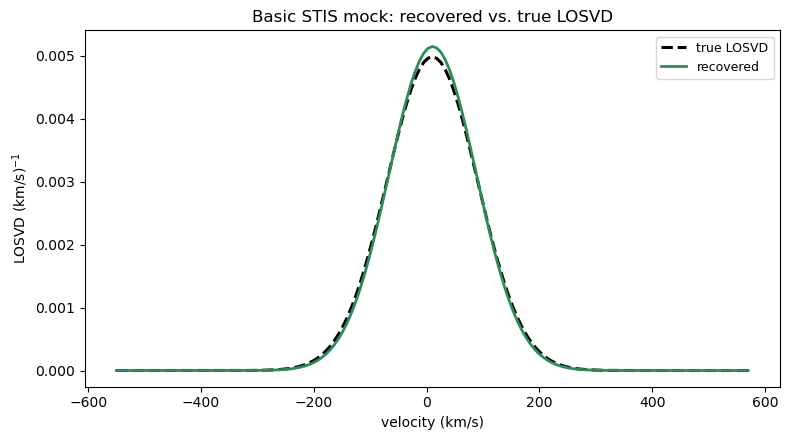

In [2]:
MOCK_TEMPLATES = templates[:3]
MOCK_TRUE_V, MOCK_TRUE_SIGMA, MOCK_SNR = 10.0, 80.0, 70.0
MOCK_TRUE_W = np.array([0.3, 0.4, 0.3])

cfg_basic = FitConfig(vmin=MOCK_TRUE_V - 7 * MOCK_TRUE_SIGMA, vmax=MOCK_TRUE_V + 7 * MOCK_TRUE_SIGMA)
v_grid_basic = cfg_basic.build_velocity_grid()
b_truth_basic, _ = build_spline_truth(v_grid_basic, vel=MOCK_TRUE_V, sigma=MOCK_TRUE_SIGMA,
                                       wiggle_scale=0.0, seed=4)

A_stack_basic = build_template_stack(wave_fit, template_wave, MOCK_TEMPLATES, v_grid_basic)
galaxy_noiseless_basic = sum(MOCK_TRUE_W[k] * (A_stack_basic[k] @ b_truth_basic) for k in range(3))
noise_basic = np.median(galaxy_noiseless_basic) / MOCK_SNR
rng_basic = np.random.default_rng(4)
galaxy_basic = galaxy_noiseless_basic + rng_basic.normal(0.0, noise_basic, len(wave_fit))
errors_basic = np.full(len(wave_fit), noise_basic)

A_stack_w_basic = A_stack_basic / errors_basic[None, :, None]
y_w_basic = galaxy_basic / errors_basic
result_basic = fit_losvd(A_stack_w_basic, y_w_basic, cfg_basic)
moments_basic = compute_losvd_moments(v_grid_basic, result_basic['b'], fit_h3h4=True)

print(f"true:      V={MOCK_TRUE_V:+.1f} km/s  sigma={MOCK_TRUE_SIGMA:.1f} km/s")
print(f"recovered: V={moments_basic['vherm']:+.1f} km/s  sigma={moments_basic['sherm']:.1f} km/s  "
      f"h3={moments_basic['h3']:+.3f}  h4={moments_basic['h4']:+.3f}")

b_truth_basic_n = b_truth_basic / np.trapezoid(b_truth_basic, v_grid_basic)
b_fit_basic_n = result_basic['b'] / np.trapezoid(np.maximum(result_basic['b'], 0.0), v_grid_basic)
plt.figure(figsize=(8, 4.5))
plt.plot(v_grid_basic, b_truth_basic_n, color='black', lw=2.2, ls='--', label='true LOSVD')
plt.plot(v_grid_basic, b_fit_basic_n, color='seagreen', lw=2.0, label='recovered')
plt.xlabel('velocity (km/s)'); plt.ylabel(r'LOSVD (km/s)$^{-1}$')
plt.title('Basic STIS mock: recovered vs. true LOSVD'); plt.legend(fontsize=9)
plt.tight_layout(); plt.show()


## 3. A more complex mock: continuum-cofitting on STIS

Same continuum-cofitting mechanism as `02_realistic_mock_fit.ipynb`
(`fit_losvd_with_continuum`, `penalty_order=3` with a fixed `lam` in the
validated 4096-32768 range), unchanged, applied to STIS templates and
pixel sampling. Injects the same kind of nonzero-mean continuum
distortion `02_realistic_mock_fit.ipynb` uses.

**The same continuum-mean limitation documented in
`kinextract.continuum`'s own module docstring shows up here too, not
just on MUSE/E-MILES mocks** -- expected, since it's a property of the
`(b, w, C)` parametrization itself, not of any one instrument or template
set (see that docstring's "`C`'s recovered absolute mean is not
identifiable" section for the mechanism). Watch the kinematics (still
accurate) against the recovered continuum's *shape* (still accurate) vs.
its absolute level (not expected to match).

true:      V=+10.0 km/s  sigma=80.0 km/s
recovered: V=+10.8 km/s  sigma=81.0 km/s  h3=+0.000  h4=+0.000
true continuum mean=1.095  recovered continuum mean=1.001  (see markdown above -- not expected to match)


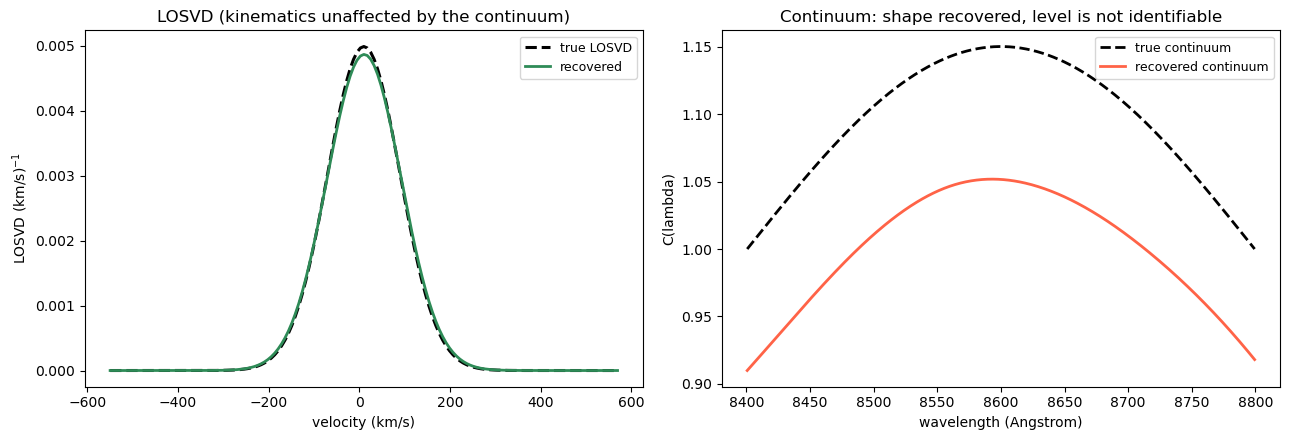

In [3]:
frac = (wave_fit - wave_fit.min()) / (wave_fit.max() - wave_fit.min())
true_C = 1.0 + 0.15 * np.sin(np.pi * frac)  # same nonzero-mean distortion 02_realistic_mock_fit.ipynb uses

galaxy_noiseless_cont = galaxy_noiseless_basic * true_C  # reuse Section 2's own true LOSVD/mixture
noise_cont = np.median(galaxy_noiseless_cont) / MOCK_SNR
rng_cont = np.random.default_rng(5)
galaxy_cont = galaxy_noiseless_cont + rng_cont.normal(0.0, noise_cont, len(wave_fit))
errors_cont = np.full(len(wave_fit), noise_cont)
y_w_cont = galaxy_cont / errors_cont
A_stack_w_cont = A_stack_basic / errors_cont[None, :, None]

n_knots_basic = cfg_basic.resolved_n_interior_knots()
basis_cont, n_coef_cont = build_bspline_basis(v_grid_basic, n_interior_knots=n_knots_basic, degree=cfg_basic.degree)
dv_cont = (cfg_basic.vmax - cfg_basic.vmin) / (n_knots_basic + 1)
D2_cont = difference_matrix(n_coef_cont, order=3, dv=dv_cont, dv_ref=cfg_basic.knot_spacing_kms)

result_cont = fit_losvd_with_continuum(A_stack_w_cont, y_w_cont, wave_fit, basis_cont, D2_cont,
                                        n_continuum_knots=4, lam=4096.0)
moments_cont = compute_losvd_moments(v_grid_basic, result_cont['b'], fit_h3h4=True)

print(f"true:      V={MOCK_TRUE_V:+.1f} km/s  sigma={MOCK_TRUE_SIGMA:.1f} km/s")
print(f"recovered: V={moments_cont['vherm']:+.1f} km/s  sigma={moments_cont['sherm']:.1f} km/s  "
      f"h3={moments_cont['h3']:+.3f}  h4={moments_cont['h4']:+.3f}")
print(f"true continuum mean={true_C.mean():.3f}  recovered continuum mean={result_cont['C'].mean():.3f}  "
      f"(see markdown above -- not expected to match)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
b_fit_cont_n = result_cont['b'] / np.trapezoid(np.maximum(result_cont['b'], 0.0), v_grid_basic)
axes[0].plot(v_grid_basic, b_truth_basic_n, color='black', lw=2.2, ls='--', label='true LOSVD')
axes[0].plot(v_grid_basic, b_fit_cont_n, color='seagreen', lw=2.0, label='recovered')
axes[0].set_xlabel('velocity (km/s)'); axes[0].set_ylabel(r'LOSVD (km/s)$^{-1}$')
axes[0].set_title('LOSVD (kinematics unaffected by the continuum)'); axes[0].legend(fontsize=9)

axes[1].plot(wave_fit, true_C, color='black', lw=2.0, ls='--', label='true continuum')
axes[1].plot(wave_fit, result_cont['C'], color='tomato', lw=2.0, label='recovered continuum')
axes[1].set_xlabel('wavelength (Angstrom)'); axes[1].set_ylabel('C(lambda)')
axes[1].set_title('Continuum: shape recovered, level is not identifiable'); axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()


## 4. Load the real spectrum, deredshift, and restrict to the fit window

A real, pre-extracted STIS spectrum (`.norm`) and its noise level
(`.rms`) for the innermost spatial bin of the same NGC 5102 target the
MUSE notebooks use. Real data outside this vendored bin lives outside
this repo -- this is the one bin vendored into `examples/data/stis/` for
portability. Same CaII-triplet fit window convention as the MUSE notebook
(8400-8800 Angstrom rest-frame) -- STIS's own observed range here
(8275-8846 Angstrom) comfortably contains it.

bin0105: 1024 pixels, 8275.0-8846.4 Angstrom (observed frame)
per-pixel noise level (from .rms): 0.02669
fit window: 8400-8800 Angstrom rest-frame, 717 pixels


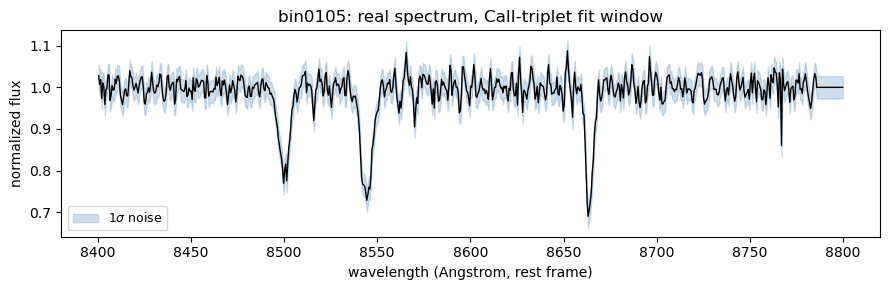

In [4]:
BINNAME = "bin0105"    # the innermost bin, same convention as the MUSE notebook
Z = 0.0016181          # NGC 5102's own systemic redshift (same target, same value as the MUSE notebook)

d = np.loadtxt(f"{DATA_DIR}/{BINNAME}sp.norm")
wave_obs, flux_obs = d[:, 0], d[:, 1]
noise_level = float(np.loadtxt(f"{DATA_DIR}/{BINNAME}sp.rms")[0])
print(f"{BINNAME}: {len(wave_obs)} pixels, {wave_obs[0]:.1f}-{wave_obs[-1]:.1f} Angstrom (observed frame)")
print(f"per-pixel noise level (from .rms): {noise_level:.4g}")

wave_rest = wave_obs / (1.0 + Z)
in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
wave_fit = wave_rest[in_window]  # overwrites Sections 2-3's own placeholder wave_fit with the real data's grid
flux_fit = flux_obs[in_window]
print(f"fit window: {WAVEFITMIN:.0f}-{WAVEFITMAX:.0f} Angstrom rest-frame, {len(wave_fit)} pixels")

plt.figure(figsize=(9, 3))
plt.plot(wave_fit, flux_fit, lw=1.0, color='black')
plt.fill_between(wave_fit, flux_fit - noise_level, flux_fit + noise_level,
                  color='steelblue', alpha=0.25, label=r'1$\sigma$ noise')
plt.xlabel('wavelength (Angstrom, rest frame)'); plt.ylabel('normalized flux')
plt.legend(fontsize=9); plt.title(f'{BINNAME}: real spectrum, CaII-triplet fit window')
plt.tight_layout(); plt.show()


## 5. Fit, using a self-contained two-stage grid

Same two-stage approach as the MUSE notebook: fit once on a generous,
fixed default grid to get a rough (V, sigma) estimate, then refit on a
properly-centered `V -+ 7*sigma` grid built from that -- no external
reference value needed.

Stage 1 (rough estimate, +-400 km/s grid): V=+66.9  sigma=61.0


Stage 2 grid: (-360, 494) km/s
success  : True  (CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH)
chi2_red : 1.054   S/N (estimated): 37

V     = +68.30 km/s
sigma = 61.71 km/s
h3    = +0.0280
h4    = +0.0012


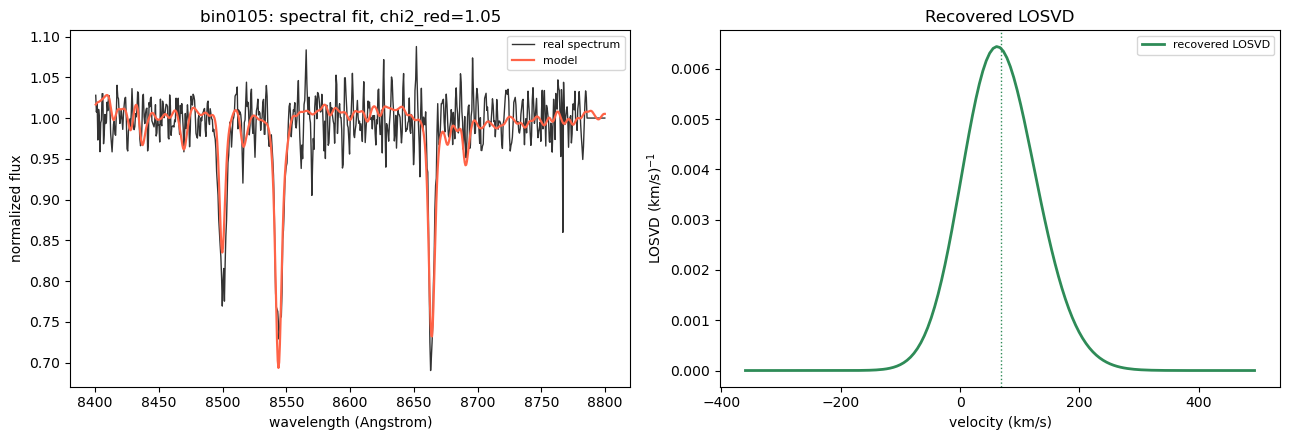

In [5]:
errors = np.full(len(wave_fit), noise_level)
y_w = flux_fit / errors

# Stage 1: a generous, fixed default grid -- rough estimate only.
cfg_wide = FitConfig(vmin=-400.0, vmax=400.0)
v_grid_wide = cfg_wide.build_velocity_grid()
A_stack_wide = build_template_stack(wave_fit, template_wave, templates, v_grid_wide)
A_stack_w_wide = A_stack_wide / errors[None, :, None]
result_wide = fit_losvd(A_stack_w_wide, y_w, cfg_wide)
moments_wide = compute_losvd_moments(v_grid_wide, result_wide['b'], fit_h3h4=False)
print(f"Stage 1 (rough estimate, +-400 km/s grid): V={moments_wide['vherm']:+.1f}  sigma={moments_wide['sherm']:.1f}")

# Stage 2: refit on a properly-centered V -+ 7*sigma grid built from the Stage 1 estimate.
NSIG = 7
cfg = FitConfig(vmin=moments_wide['vherm'] - NSIG * moments_wide['sherm'],
                vmax=moments_wide['vherm'] + NSIG * moments_wide['sherm'])
v_grid = cfg.build_velocity_grid()

A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
A_stack_w = A_stack / errors[None, :, None]

result = fit_losvd(A_stack_w, y_w, cfg)
moments = compute_losvd_moments(v_grid, result['b'], fit_h3h4=True)

A_eff_w = np.tensordot(result['w'], A_stack_w, axes=([0], [0]))
model_w = A_eff_w @ result['b']
snr_est = estimate_snr_whitened(model_w)
resid = model_w - y_w
chi2_red = float(np.sum(resid**2)) / len(wave_fit)

print(f"Stage 2 grid: ({cfg.vmin:.0f}, {cfg.vmax:.0f}) km/s")
print(f"success  : {result['success']}  ({result['message']})")
print(f"chi2_red : {chi2_red:.3f}   S/N (estimated): {snr_est:.0f}")
print()
print(f"V     = {moments['vherm']:+.2f} km/s")
print(f"sigma = {moments['sherm']:.2f} km/s")
print(f"h3    = {moments['h3']:+.4f}")
print(f"h4    = {moments['h4']:+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(wave_fit, flux_fit, lw=1.0, color='black', alpha=0.8, label='real spectrum')
ax.plot(wave_fit, model_w * errors, lw=1.6, color='tomato', label='model', zorder=3)
ax.set_xlabel('wavelength (Angstrom)'); ax.set_ylabel('normalized flux')
ax.set_title(f'{BINNAME}: spectral fit, chi2_red={chi2_red:.2f}'); ax.legend(fontsize=8)

ax = axes[1]
b_n = result['b'] / np.trapezoid(np.maximum(result['b'], 0.0), v_grid)
ax.plot(v_grid, b_n, color='seagreen', lw=2.0, label='recovered LOSVD')
ax.axvline(moments['vherm'], color='seagreen', ls=':', lw=1.0)
ax.set_xlabel('velocity (km/s)'); ax.set_ylabel(r'LOSVD (km/s)$^{-1}$')
ax.set_title('Recovered LOSVD'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 6. Grid-width stability, and a cross-instrument comparison

Checked directly, not assumed: does the Stage 1 estimate above depend on
exactly how wide "generous" is? A range of grid widths gives a consistent
answer -- `V` and `sigma` both stable to within a few km/s across
`+-250` to `+-500 km/s`. (A `+-600 km/s` grid was also tried and found to
jump to a different, competing solution -- the same kind of wide-grid
multi-modality this package's own real-MUSE-data notebooks document for
different bins/instruments/template libraries. `+-400 km/s`, used above,
sits safely inside the stable range found here.)

That stability is itself the interesting result: this bin's own `V` is
*not* noisy or ill-determined -- it is a real, repeatable ~68 km/s,
consistently, regardless of grid width. `05_noise_correlation.ipynb`'s
own properly-whitened fit of the nominally-same nuclear aperture recovers
`V=-6.9` km/s instead -- a ~75 km/s disagreement. Both results are
internally stable (Stage-1-vs-Stage-2 here, grid-width sweep above); they
simply disagree with each other by a large, structured amount.

The `sigma` comparison: **STIS 61.7 vs. MUSE 45.0** km/s, a ~37% difference
with STIS higher. `h3` also disagrees: `+0.028` here vs. `+0.017` there --
both positive, but not close enough to call the same value within this
bin's own uncertainty (Section 7).

Plausible contributors to this real, unresolved disagreement: a genuine
wavelength-zeropoint difference between this STIS template library and
this science exposure (the leading candidate for the `V` offset, though
it would leave `sigma`/`h3` largely unaffected, so it is not the whole
story on its own); the very different template subsets (50 real STIS
stars vs. a handful of E-MILES templates from an iterative reduction);
and this bin's own noise-driven wing-amplitude sensitivity (`lam_wing=0`
here, in the low-sigma/many-template regime `PARAMETER_GUIDE.md` flags
as needing it tuned -- see the `wing_mass` diagnostic below). Presented
as an open, honest discrepancy, not resolved in this notebook.

In [ ]:
print(f"{'grid half-width':>16}  {'V':>8}  {'sigma':>8}")
for vlim in [250.0, 300.0, 350.0, 450.0, 500.0]:
    cfg_test = FitConfig(vmin=-vlim, vmax=vlim)
    v_grid_test = cfg_test.build_velocity_grid()
    A_stack_test = build_template_stack(wave_fit, template_wave, templates, v_grid_test)
    A_stack_w_test = A_stack_test / errors[None, :, None]
    result_test = fit_losvd(A_stack_w_test, y_w, cfg_test)
    m_test = compute_losvd_moments(v_grid_test, result_test['b'], fit_h3h4=False)
    print(f"{vlim:>14.0f}  {m_test['vherm']:>+8.1f}  {m_test['sherm']:>8.1f}")
print(f"\n(05_noise_correlation.ipynb's own nuclear/high-S/N aperture, properly rho-whitened: "
      f"V=-6.9, sigma=45.0)")

# wing-amplitude diagnostic: is the recovered LOSVD carrying spurious mass far from its
# own core, the signature `lam_wing` exists to suppress (lam_wing=0.0, the default, is
# used everywhere in this notebook)?
b_n_diag = result['b'] / np.trapezoid(np.maximum(result['b'], 0.0), v_grid)
core_diag = b_n_diag > 0.01 * b_n_diag.max()
wing_mass_diag = np.trapezoid(b_n_diag[~core_diag], v_grid[~core_diag]) if (~core_diag).any() else 0.0
print(f"wing_mass (LOSVD mass outside the >1%-of-peak core, unit area): {wing_mass_diag:.4f}")
print("(a nonzero lam_wing has not been tuned for this 50-template real mixture at S/N~37 --")
print(" not attempted here for lack of ground truth to validate against on real data;")
print(" see PARAMETER_GUIDE.md.)")

## 7. Uncertainty

`laplace_losvd_uncertainty`'s single-lam mode (`quick_laplace_uncertainty`)
is this package's fast default uncertainty check; `bootstrap_losvd`
remains available as a cross-check (real ensemble properties Laplace
can't give). Given Section 6's finding, this bin's own uncertainty below
reflects fit-to-fit noise at fixed grid centering -- it does not capture
the separate, structured disagreement with the MUSE notebook's own
result, which is a different kind of uncertainty (model/calibration, not
sampling) that neither method is designed to quantify.

**Read the shaded band below as "what a typical refit at this noise level
looks like," not as a strict confidence interval guaranteed to contain
the green point-estimate curve.** Both engines here have real, measured,
imperfect coverage in general (see `kinextract.laplace_uncertainty`'s own
module docstring). This bin (`lam_wing=0`, low-sigma, many-template) is
in the regime `PARAMETER_GUIDE.md` flags as needing extra care regardless
of this separate finding.

The numbers below are raw, uncorrected estimates. A post-hoc
regularization-bias correction exists but is **not applied by default**,
and even more so here than on MUSE data: the shipped calibration is
built on E-MILES templates at MUSE pixel sampling -- a real STIS stellar
library at STIS sampling is a further, untested extrapolation on top of
the overcorrection failure modes already found within the calibration's
own nominal (MUSE, E-MILES) domain.

                               V         sigma          h3          h4
   Laplace (quick)   +68.3 +/- 4.2     61.7 +/- 4.7  +0.028 +/- 0.041 +0.001 +/- 0.022
         bootstrap   +68.3 +/- 2.6     61.7 +/- 3.6  +0.028 +/- 0.011 +0.001 +/- 0.001


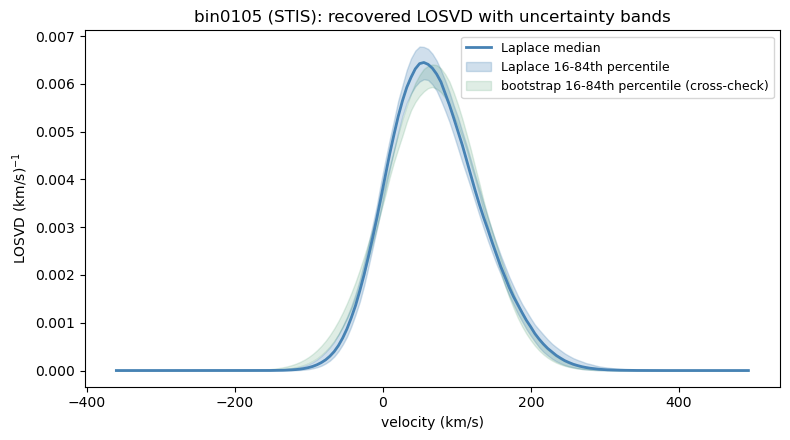

In [7]:
quick = quick_laplace_uncertainty(A_stack_w, y_w, cfg, n_samples=200, seed=0)
boot = bootstrap_losvd(A_stack_w, y_w, cfg, n_boot=30, seed=0)

print(f"{'':>18}{'V':>14}{'sigma':>14}{'h3':>12}{'h4':>12}")
print(f"{'Laplace (quick)':>18}{moments['vherm']:>+8.1f} +/- {quick['vherm_std']:<4.1f}"
      f"{moments['sherm']:>8.1f} +/- {quick['sherm_std']:<4.1f}"
      f"{moments['h3']:>+7.3f} +/- {quick['h3_std']:<4.3f}"
      f"{moments['h4']:>+7.3f} +/- {quick['h4_std']:<4.3f}")
print(f"{'bootstrap':>18}{moments['vherm']:>+8.1f} +/- {boot['vherm_std']:<4.1f}"
      f"{moments['sherm']:>8.1f} +/- {boot['sherm_std']:<4.1f}"
      f"{moments['h3']:>+7.3f} +/- {boot['h3_std']:<4.3f}"
      f"{moments['h4']:>+7.3f} +/- {boot['h4_std']:<4.3f}")

# Report the MEDIAN uncertainty-engine curve, not the raw point estimate -- the
# percentile band is centered on the median by construction, not on the point
# estimate, so plotting the point estimate as "the answer" next to a band it
# isn't centered on would be misleading (Laplace is this package's default
# engine; shown here as the reported curve, bootstrap as the cross-check band).
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(v_grid, quick['b_median'], color='steelblue', lw=2.0, label='Laplace median')
ax.fill_between(v_grid, quick['b_p16'], quick['b_p84'],
                 color='steelblue', alpha=0.25, label='Laplace 16-84th percentile')
ax.fill_between(v_grid, boot['b_p16'], boot['b_p84'],
                 color='seagreen', alpha=0.15, label='bootstrap 16-84th percentile (cross-check)')
ax.set_xlabel('velocity (km/s)'); ax.set_ylabel(r'LOSVD (km/s)$^{-1}$')
ax.set_title(f'{BINNAME} (STIS): recovered LOSVD with uncertainty bands')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


## Conclusion

**What this notebook did.** Adapted the exact same fitting engine used
throughout this package -- `fit_losvd`, `bootstrap_losvd`,
`quick_laplace_uncertainty`, continuum-cofitting -- to a completely
different instrument (HST/STIS) and a completely different template
source (50 real observed stellar spectra, no synthetic grid, no LSF
matching needed), then fit a real spectrum with it.

**Key takeaways:**

- Nothing about the fitting engine is MUSE- or E-MILES-specific. Both
  mocks recovered their injected LOSVDs correctly on STIS's own pixel
  sampling and template library, continuum-cofitting included.
- Adapting `kinextract` to a new instrument is a template-and-data
  question, not a code change: load your own templates and data at their
  own native sampling, and the same `FitConfig`/`fit_losvd` calls apply
  unchanged.
- **The real fit surfaced an honest, unresolved disagreement**: this
  STIS bin's own `V`, `sigma`, and `h3` all differ substantially and
  *stably* from a MUSE fit of the nominally-same nuclear aperture.
  Repeatable across a grid-width sweep, so not noise -- a real,
  structured difference between what the two instruments/template
  libraries give for this target, with no independent ground truth here
  to say which (if either) is closer to correct.
- This bin also sits in the regime this package's own parameter guidance
  flags as needing `lam_wing` tuned (low sigma, many templates, S/N~37) --
  not attempted here for lack of ground truth to validate a chosen value
  against on real data.

**Next**: this is the last notebook in the sequence. `07_full_galaxy_analysis.ipynb`
is the capstone if you haven't run it yet -- the same pipeline, at real
scale, on MUSE data with a properly calibrated template subset. If you're
adapting `kinextract` to your own instrument, the three-step progression
here (basic mock -> complex mock -> real fit) is the template to follow
with your own data.

See `kinextract.uncertainty`'s/`kinextract.laplace_uncertainty`'s/
`kinextract.bias_correction`'s own module docstrings for the
uncertainty-engine designs and regularization-bias correction.